In [2]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy.stats as stats
import scienceplots as sp
plt.style.use('science')
sys.path.insert(0, '../../')

from Preprocessing.ng_loader import df_all_cycles, cycles
from Generation_data_scripts.Eclipse_ng_gen import generate_all_scripts
from Preprocessing.ng_cycles_stats import calculate_cycles, plot_cycle_histogram, plot_rate_distribution, country_cycle_stats

directory_path = '../../data/Agsi_data_depleted/'

df_all = df_all_cycles(directory_path, MAXrate=6*(10**5), time_unit='months')

In [3]:
df_all.columns

Index(['Country', 'Site', 'Month', 'Injection_GWh_d', 'Withdrawal_GWh_d',
       'Gas_in_storage_TWh', 'Full_percent', 'Technical_Capacity_TWh',
       'Injection_capacity_GWh/d', 'Withdrawal_capacity_GWh_d',
       'Contracted_Capacity_TWh', 'Available_Capacity_TWh', 'Phase',
       'Net_Injection_Withdrawal_GWh_d', 'Normalised_Net_Injection_Withdrawal',
       'Phase_Change', 'Cycle_ID', 'Row_Script', 'Cycle_position',
       'Normalised_cycle_pos', 'Normalised_cycle_pos_cut'],
      dtype='object')

Text(0.5, 1.0, 'Number of Injection Cycles by Country')

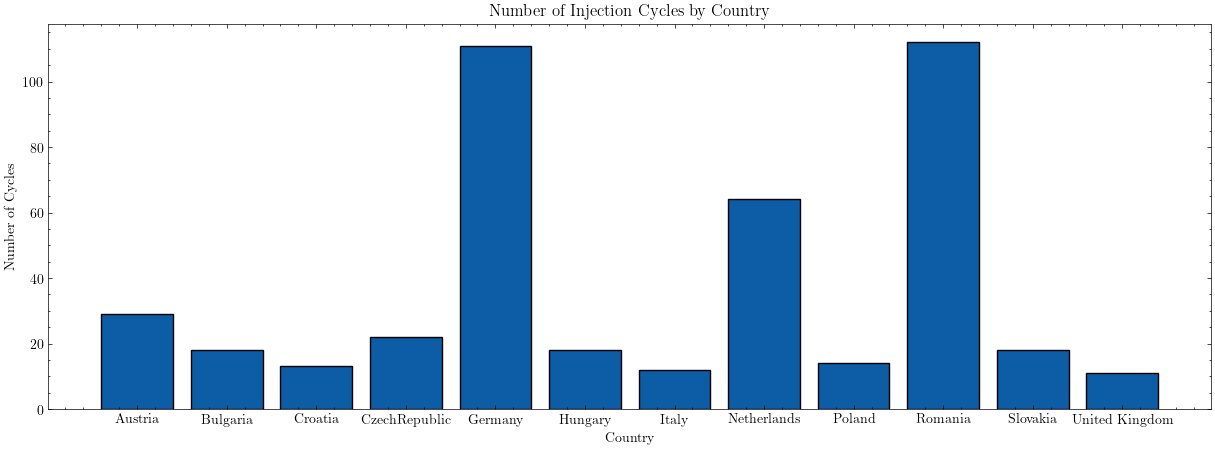

In [4]:
country_cycle_dict_withdrawal, country_cycle_dict_injection, country_cycle_dict_idle, inject_cycles, withdrawal_cycles, idle_cycles = country_cycle_stats(df_all)



# for country in country_cycle_dict_withdrawal.keys():
#     with_dict = country_cycle_dict_withdrawal[country]
#     inj_dict = country_cycle_dict_injection[country]
#     idle_dict = country_cycle_dict_idle[country]

#     with_list = country_cycle_dict_withdrawal[country]
#     inj_list = country_cycle_dict_injection[country]
#     idle_list = country_cycle_dict_idle[country]

#     inj_lengths = inj_list[0]
#     inj_amounts = inj_list[1]

#     with_lengths = with_list[0]
#     with_amounts = with_list[1]

#     idle_lengths = idle_list[0]   # idle only ever stored one element
#     inject_cyles[country] = len(inj_lengths)
#     withdrawal_cycles[country] = len(with_lengths)
#     idle_cycles[country] = len(idle_lengths)

#     fig, axs = plt.subplots(figsize=(15, 5))
#     axs.bar(np.arange(len(inj_lengths)), inj_lengths, label='Injection', alpha=0.5)
#     axs.bar(np.arange(len(with_lengths)), with_lengths, label='Withdrawal', alpha=0.5)
#     axs.bar(np.arange(len(idle_lengths)), idle_lengths, label='Idle', alpha=0.5)
#     axs.set_xlabel('Cycle Index')
#     axs.set_ylabel('Cycle Length (Months)')
#     axs.set_title(f'Cycle Lengths for {country}')
#     axs.legend()

fig, axs = plt.subplots(figsize=(15, 5))
axs.bar(inject_cycles.keys(), ((inject_cycles.values())), label='Injection', alpha=1, edgecolor='black')
axs.set_xlabel('Country')
axs.set_ylabel('Number of Cycles')
axs.set_title('Number of Injection Cycles by Country')

# fig, axs = plt.subplots(figsize=(15, 5))
# axs.bar(withdrawal_cycles.keys(), ((withdrawal_cycles.values())/ ((inject_cycles.values()) + (withdrawal_cycles.values()) + (idle_cycles.values()))), label='Withdrawal', alpha=1, edgecolor='black')
# axs.set_xlabel('Country')
# axs.set_ylabel('Number of Cycles')
# axs.set_title('Number of Withdrawal Cycles by Country')

# fig, axs = plt.subplots(figsize=(15, 5))
# axs.bar(idle_cycles.keys(), idle_cycles.values(), label='Idle', alpha=1, edgecolor='black')
# axs.set_xlabel('Country')
# axs.set_ylabel('Number of Cycles')
# axs.set_title('Number of Idle Cycles by Country')




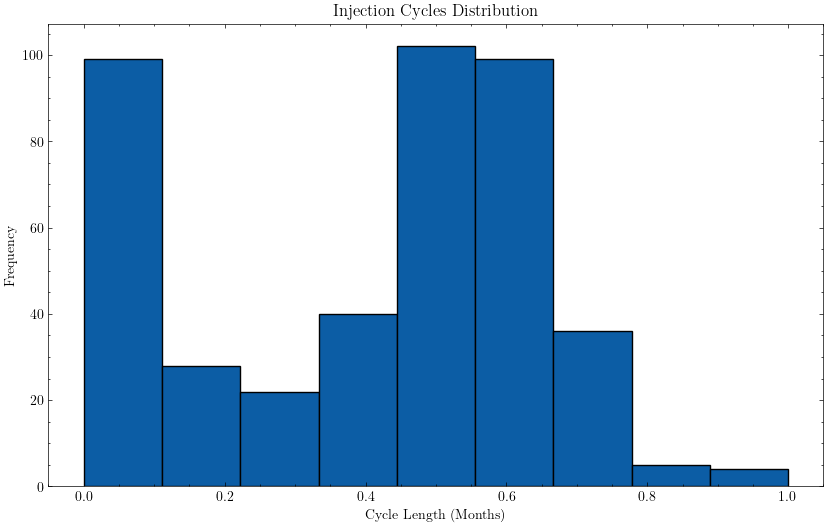

<class 'numpy.ndarray'>
0.4020689655172414 0.24024957297094815 0.5
4.28216704288939 1.9518637962456336 5.0
1.9827586206896552 1.2246235073848113 1.5


In [5]:
inj_dict, with_dict, idle_dict, _ = calculate_cycles(df_all)

inj_lengths = (inj_dict['injection_lengths_normalized'])
with_lengths = (with_dict['withdrawal_lengths'])
idle_lengths = (idle_dict['idle_lengths'])
plot_cycle_histogram(inj_lengths, phase='inj' ,title='Injection Cycles Distribution', xlabel='Cycle Length (Months)', ylabel="Frequency")
print(type(inj_lengths))
print(np.mean(inj_lengths), np.std(inj_lengths), np.median(inj_lengths))
print(np.mean(with_lengths), np.std(with_lengths), np.median(with_lengths))
print(np.mean(idle_lengths), np.std(idle_lengths), np.median(idle_lengths))

df_all['Phase'].to_csv('all_cycles.csv', index=False)


In [6]:
inj_dict['injection_lengths']

array([ 5,  4,  6,  1,  8,  8,  1,  2,  3,  1,  2,  1,  1,  6,  6,  7,  7,
        7,  7,  1,  3,  6,  8,  5,  1,  7,  6,  4,  3,  2,  4,  6,  5,  2,
        5,  7,  7,  6,  7,  5,  6,  8,  7,  6,  6,  2,  7,  5,  6,  7,  7,
        8,  6,  6,  8,  6,  6,  5,  3,  2,  3,  5,  1,  7,  6,  3,  5,  7,
        6,  6,  5,  2,  7,  3,  1,  4,  7,  2,  6,  2,  6,  4,  1,  5,  8,
        5,  1,  5,  2,  1,  1,  6,  1,  1,  1,  2,  1,  1,  1,  7,  8,  6,
        8,  6,  2,  8,  8,  7,  9,  1,  1,  2,  7,  1,  8,  7,  1,  4,  1,
        6,  3,  7,  1,  5,  7,  7, 10,  7,  8,  7,  9,  7,  7,  8,  8,  6,
        6,  2,  6,  6,  1,  6,  7,  6,  1,  6,  8,  7,  7,  5,  6,  4,  3,
        6,  6,  1,  3,  1,  1,  1,  1,  7,  6,  7,  7,  7,  7,  3,  1,  1,
        2,  1,  8,  1,  7,  8,  4,  3,  1,  6,  7,  7,  6,  1,  5,  1,  6,
        8,  7,  8,  6,  2,  6,  8,  5,  9,  7,  6,  6,  8,  7,  7,  7,  6,
        8,  7,  7,  7,  5,  7,  6,  6,  7,  6,  7,  1,  6,  6,  7,  7,  2,
        6,  1,  4, 11,  1

(array([ 66.,  33.,  28.,  22.,  40., 102.,  99.,  36.,   5.,   4.]),
 array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.]),
 <BarContainer object of 10 artists>)

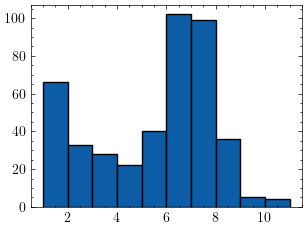

In [7]:
plt.hist(inj_dict['injection_lengths'], label='Injection', alpha=1, edgecolor='black')

In [8]:
#plot_rate_distribution(df_all, cycle='withdrawal', Position=None, All=True, norm=True)

/tmp/ipykernel_12262/1239612946.py:1: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  df_all['Normalised_cycle_pos'] = (df_all['Cycle_position'] / df_all.groupby(by=['Site', 'Cycle_ID'])['Cycle_position'].transform(max))


(array([  7., 173., 206., 166., 255., 314.,  45., 279.,  11., 422., 132.,
        158., 355., 125., 134., 166., 327.,  56.,   3., 995.]),
 array([0.05555556, 0.10277778, 0.15      , 0.19722222, 0.24444444,
        0.29166667, 0.33888889, 0.38611111, 0.43333333, 0.48055556,
        0.52777778, 0.575     , 0.62222222, 0.66944444, 0.71666667,
        0.76388889, 0.81111111, 0.85833333, 0.90555556, 0.95277778,
        1.        ]),
 <BarContainer object of 20 artists>)

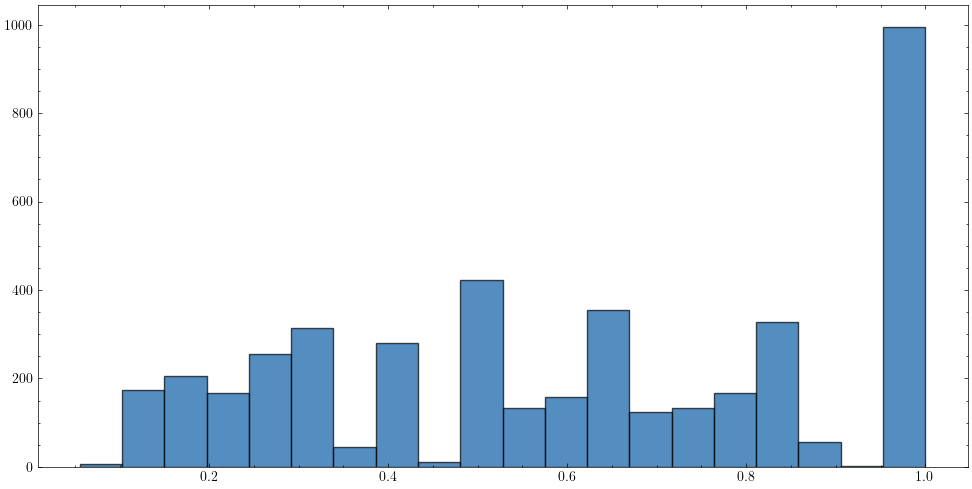

In [9]:
df_all['Normalised_cycle_pos'] = (df_all['Cycle_position'] / df_all.groupby(by=['Site', 'Cycle_ID'])['Cycle_position'].transform(max))

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df_all['Normalised_cycle_pos'], bins=20, edgecolor='black', alpha=0.7)

/home/tlp25/irp-tlp25/exploratory/Natural_Gas/../../Preprocessing/ng_cycles_stats.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_cycle_months = df_all.groupby(


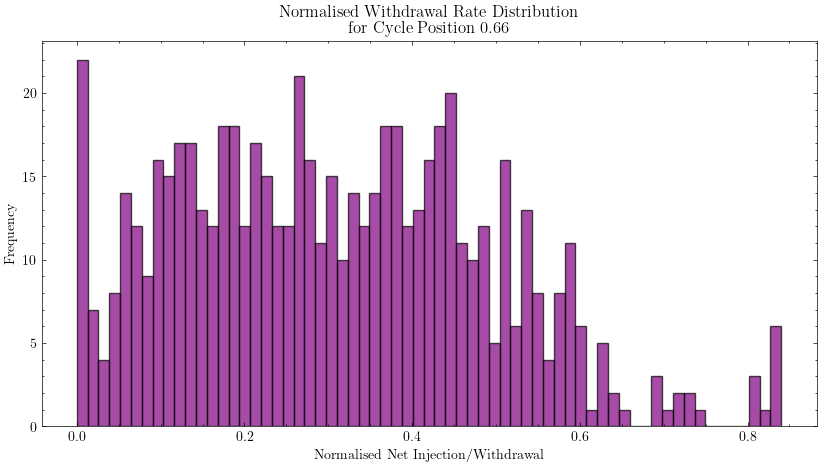

In [37]:
plot_rate_distribution(df_all, cycle='withdrawal', Position=0.66, All=False, norm=True)


(array([ 73.,  77., 112., 137., 143., 156., 170., 214., 225., 317., 335.,
        387., 337., 301., 318., 220., 344., 175., 147., 141.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

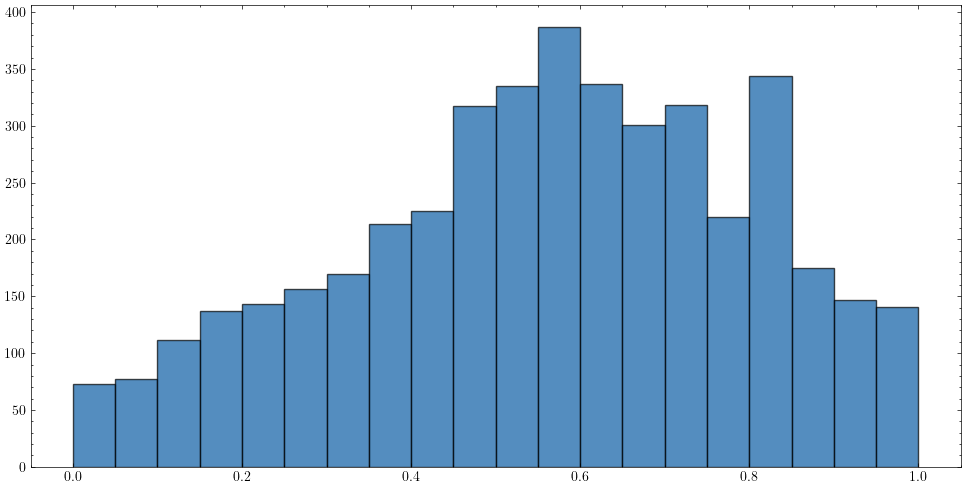

In [35]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df_all['Normalised_Net_Injection_Withdrawal'], bins=20, edgecolor='black', alpha=0.7)

### Testing to see if there is a measurable correlation between cycle length and the subsequent cycle length.

The results show a weak correlation so when generating the synthetic dataset the length of the previous cycle will not be used to determine the following cycle length.

| Preceding Cycle Type | Pearson r | Pearson p | Pearson R² | Spearman ρ | Spearman p | Spearman R² |
|----------------------|-----------|-----------|------------|------------|------------|-------------|
| Idle                 | -0.046    | 0.627     | 0.002      | -0.024     | 0.800      | 0.001       |
| Withdrawal           | 0.361     | 0.000     | 0.130      | 0.258      | 0.000      | 0.067       |
| Injection            | 0.311     | 0.000     | 0.097      | 0.304      | 0.000      | 0.092       |

The table was created with the help of Anthropic's Claude, the values and code were generated by myself.



<class 'pandas.core.indexes.base.Index'>
Pearson correlation: 0.361, p-value: 0.000
Pearson R^2: 0.130
Spearman correlation: 0.258, p-value: 0.000
Spearman R^2: 0.067


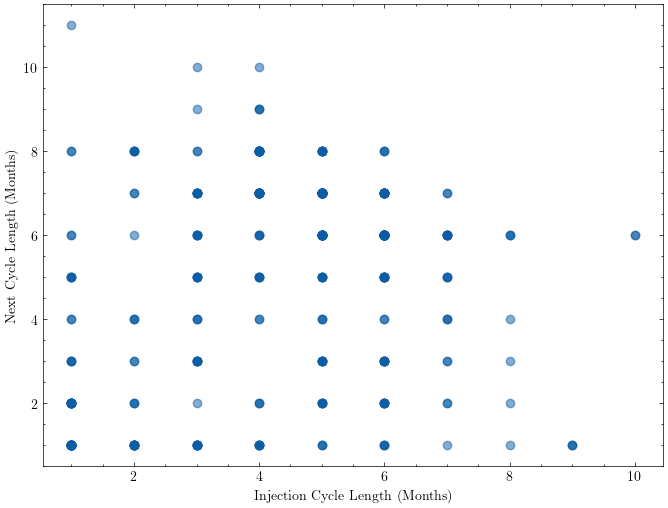

In [11]:
from scipy.stats import pearsonr

cycle_len_idx = df_all.groupby(['Site', 'Cycle_ID'])['Cycle_position'].idxmax() # find idx of last row of each cycle

df3 = df_all.loc[cycle_len_idx].copy() # only keep the last row of each cycle, which contains the length of the cycle
df3 = df3[df3['Cycle_position'].isin(df3['Cycle_position'].value_counts()[df3['Cycle_position'].value_counts() > 1].index)] #This drops any cycle lengths that only occur once.
df3.reset_index(drop=True, inplace=True)

df4 = df3[:-1] #removing last item as it leads to index error.
inj_idx = df4[df4['Phase'] == 'withdrawal'].index # Changing this to either 'idle' or 'withdrawal' also works and give the results for those phases.
print(type(inj_idx))


inj_lens = df3.loc[inj_idx, 'Cycle_position'].values
next_phases = df3.loc[(inj_idx + 1), 'Cycle_position'].values

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(inj_lens, next_phases, alpha=0.5)
ax.set_xlabel('Injection Cycle Length (Months)')
ax.set_ylabel('Next Cycle Length (Months)')

pearson_corr, pearson_p = pearsonr(inj_lens, next_phases)
spearman_corr, spearman_p = stats.spearmanr(inj_lens, next_phases)

print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")

print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")

In [12]:
df_all.columns

Index(['Country', 'Site', 'Month', 'Injection_GWh_d', 'Withdrawal_GWh_d',
       'Gas_in_storage_TWh', 'Full_percent', 'Technical_Capacity_TWh',
       'Injection_capacity_GWh/d', 'Withdrawal_capacity_GWh_d',
       'Contracted_Capacity_TWh', 'Available_Capacity_TWh', 'Phase',
       'Net_Injection_Withdrawal_GWh_d', 'Normalised_Net_Injection_Withdrawal',
       'Phase_Change', 'Cycle_ID', 'Row_Script', 'Cycle_position',
       'Normalised_cycle_pos', 'Normalised_cycle_pos_cut'],
      dtype='object')

### Testing to see if rate is correlated to a stage in injection or cycle phase

| Variable Type           | Spearman ρ | Spearman p | Spearman R² | Pearson r | Pearson p | Pearson R² |
|--------------------------|------------|------------|-------------|-----------|-----------|------------|
| Injection Cumulative     | 0.569      | 0.000      | 0.324       | 0.315     | 0.000     | 0.099      |
| Withdrawal Cumulative    | -0.597     | 0.000      | 0.357       | -0.370    | 0.000     | 0.137      |
| Injection Rate           | -0.209     | 0.000      | 0.044       | -0.188    | 0.000     | 0.035      |
| Withdrawal Rate          | 0.083      | 0.080      | 0.007       | 0.059     | 0.216     | 0.003      |

Injection Cumulative Values
Spearman correlation: 0.569, p-value: 0.000
Spearman R^2: 0.324
Pearson correlation: 0.315, p-value: 0.000
Pearson R^2: 0.099
Withdrawal Cumulative Values
Spearman correlation: -0.597, p-value: 0.000
Spearman R^2: 0.357
Pearson correlation: -0.370, p-value: 0.000
Pearson R^2: 0.137


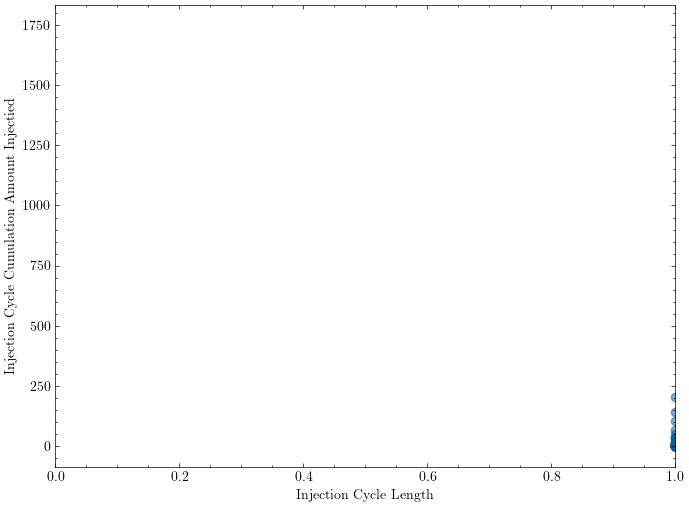

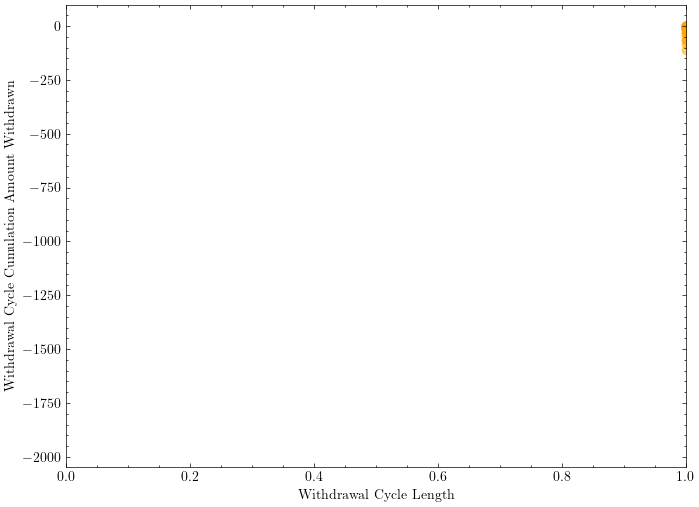

In [13]:
inj_dict, with_dict, idle_dict, _ = calculate_cycles(df_all)

inj_lengths = (inj_dict['injection_lengths'])
with_lengths = (with_dict['withdrawal_lengths'])
idle_lengths = (idle_dict['idle_lengths'])

inj_amounts = (inj_dict['injection_amounts'])
with_amounts = (with_dict['withdrawal_amounts'])

inj_rates = (inj_dict['injection_rates'])
with_rates = (with_dict['withdrawal_rates'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(inj_lengths, inj_amounts, alpha=0.5)
ax.set_xlabel('Injection Cycle Length')
ax.set_ylabel('Injection Cycle Cumulation Amount Injectied')
ax.set_xlim(0, 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(with_lengths, with_amounts, alpha=0.5, color='orange')
ax.set_xlabel('Withdrawal Cycle Length')
ax.set_ylabel('Withdrawal Cycle Cumulation Amount Withdrawn')
ax.set_xlim(0, 1)

print('Injection Cumulative Values')
spearman_corr, spearman_p = stats.spearmanr(inj_lengths, inj_amounts)
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")
pearson_corr, pearson_p = pearsonr(inj_lengths, inj_amounts)
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")

print('Withdrawal Cumulative Values')
spearman_corr, spearman_p = stats.spearmanr(with_lengths, with_amounts)
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")

pearson_corr, pearson_p = pearsonr(with_lengths, with_amounts)
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")



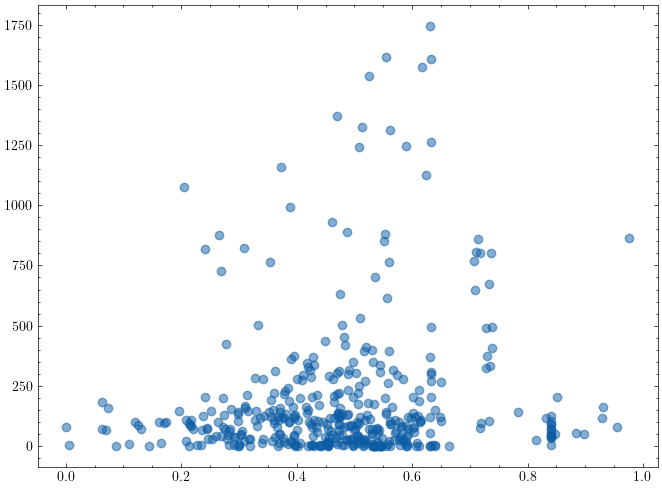

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(inj_rates, inj_amounts, alpha=0.5)

Injection Rate Values
Pearson correlation: -0.188, p-value: 0.000
Pearson R^2: 0.035
Spearman correlation: -0.209, p-value: 0.000
Spearman R^2: 0.044


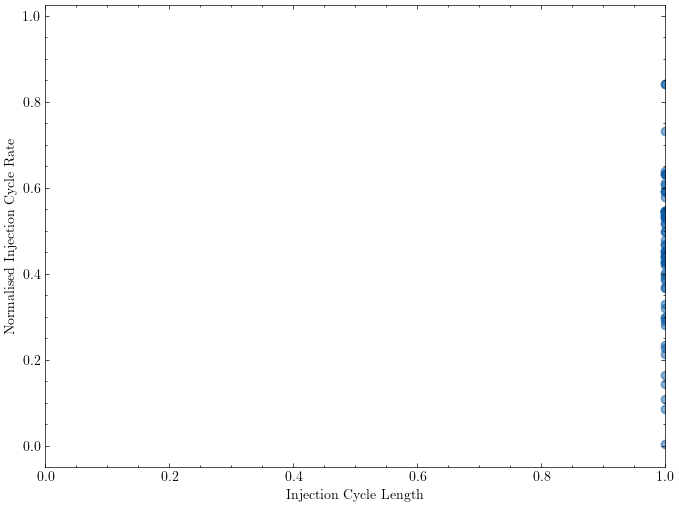

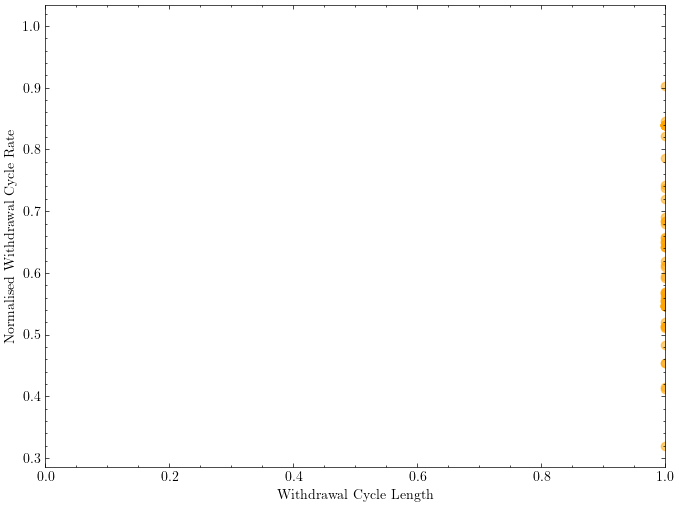

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

index_33 = df_all[(df_all['Normalised_cycle_pos_cut'] == 1) & (df_all['Phase'] == 'withdrawal')].index

df_33 = df_all.loc[index_33]

ax.scatter(inj_lengths, inj_rates, alpha=0.5)
ax.set_xlabel('Injection Cycle Length')
ax.set_ylabel('Normalised Injection Cycle Rate')
ax.set_xlim(0, 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(with_lengths, with_rates, alpha=0.5, color='orange')
ax.set_xlabel('Withdrawal Cycle Length')
ax.set_ylabel('Normalised Withdrawal Cycle Rate')
ax.set_xlim(0, 1)

pearson_corr, pearson_p = pearsonr(inj_lengths, inj_rates)
spearman_corr, spearman_p = stats.spearmanr(inj_lengths, inj_rates)

print('Injection Rate Values')
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")

435 435
Injection Length Values
Pearson correlation: 0.301, p-value: 0.000
Pearson R^2: 0.091
Spearman correlation: 0.121, p-value: 0.011
Spearman R^2: 0.015
Withdrawal Length Values
Pearson correlation: -0.431, p-value: 0.000
Pearson R^2: 0.185
Spearman correlation: -0.389, p-value: 0.000
Spearman R^2: 0.151
Idle Length Values
Pearson correlation: -0.005, p-value: 0.954
Pearson R^2: 0.000
Spearman correlation: 0.007, p-value: 0.943
Spearman R^2: 0.000


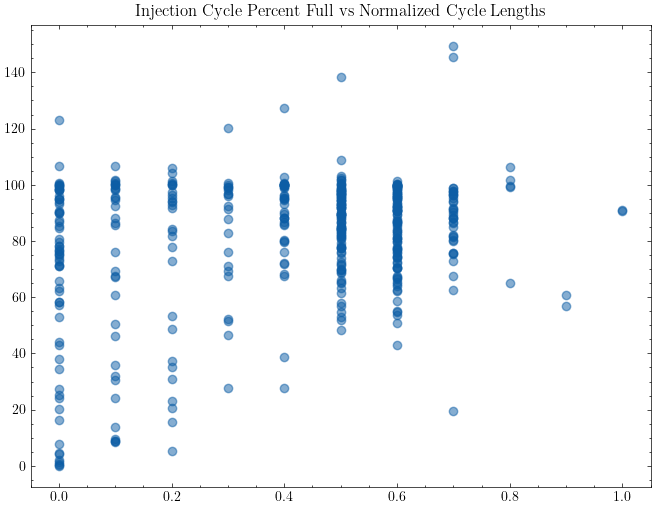

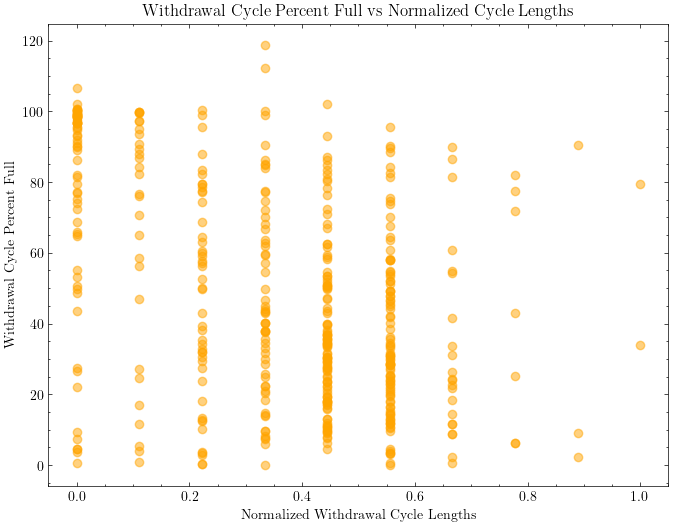

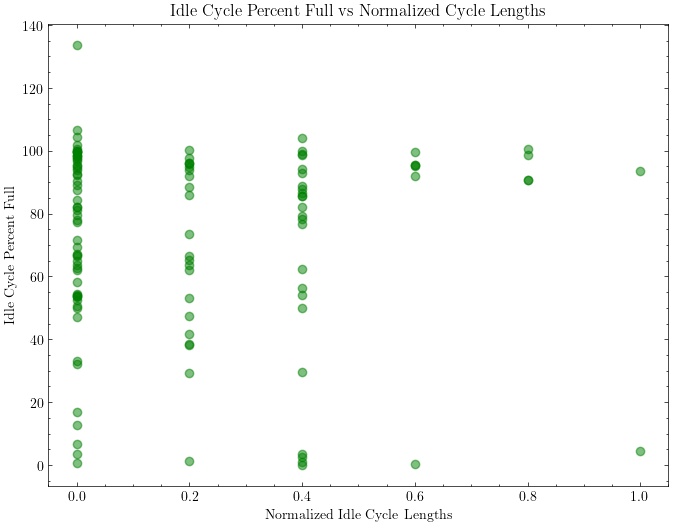

In [16]:
Inj_full = inj_dict['injection_percent_full']
Inj_cycle_lengths = inj_dict['injection_lengths_normalized']

with_full = with_dict['withdrawal_percent_full']
with_cycle_lengths = with_dict['withdrawal_lengths_normalized']

idle_full = idle_dict['idle_percent_full']
idle_cycle_lengths = idle_dict['idle_lengths_normalized']

print(len(Inj_full), len(Inj_cycle_lengths))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Inj_cycle_lengths, Inj_full, alpha=0.5)
ax.set_title('Injection Cycle Percent Full vs Normalized Cycle Lengths')


fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(with_cycle_lengths, with_full, alpha=0.5, color='orange')
ax.set_xlabel('Normalized Withdrawal Cycle Lengths')
ax.set_ylabel('Withdrawal Cycle Percent Full')
ax.set_title('Withdrawal Cycle Percent Full vs Normalized Cycle Lengths')


fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(idle_cycle_lengths, idle_full, alpha=0.5, color='green')
ax.set_xlabel('Normalized Idle Cycle Lengths')
ax.set_ylabel('Idle Cycle Percent Full')
ax.set_title('Idle Cycle Percent Full vs Normalized Cycle Lengths')

pearson_corr, pearson_p = pearsonr(Inj_cycle_lengths, Inj_full)
spearman_corr, spearman_p = stats.spearmanr(Inj_cycle_lengths, Inj_full)

print('Injection Length Values')
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")

pearson_corr, pearson_p = pearsonr(with_cycle_lengths, with_full)
spearman_corr, spearman_p = stats.spearmanr(with_cycle_lengths, with_full)

print('Withdrawal Length Values')
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")

pearson_corr, pearson_p = pearsonr(idle_cycle_lengths, idle_full)
spearman_corr, spearman_p = stats.spearmanr(idle_cycle_lengths, idle_full)

print('Idle Length Values')
print(f"Pearson correlation: {pearson_corr:.3f}, p-value: {pearson_p:.3f}")
print(f"Pearson R^2: {pearson_corr**2:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}, p-value: {spearman_p:.3f}")
print(f"Spearman R^2: {spearman_corr**2:.3f}")


In [ ]:
fr